In [1]:
# Import required libraries
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

# Load Digits dataset
digits = load_digits()

X = digits.data
y = digits.target

print("Original data shape:", X.shape)
print("Number of classes:", len(set(y)))

Original data shape: (1797, 64)
Number of classes: 10


In [2]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (1437, 64)
Testing data: (360, 64)


In [3]:
# KNN classifier
knn = KNeighborsClassifier(n_neighbors=5)

# Train model
knn.fit(X_train, y_train)

# Prediction
y_pred = knn.predict(X_test)

# Accuracy
accuracy_original = accuracy_score(y_test, y_pred)

print("Accuracy using original 64 features:",
      accuracy_original)

Accuracy using original 64 features: 0.9861111111111112


In [4]:
# Apply PCA
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X)

print("PCA data shape:", X_pca.shape)
print("Explained variance:",
      pca.explained_variance_ratio_)

PCA data shape: (1797, 2)
Explained variance: [0.14890594 0.13618771]


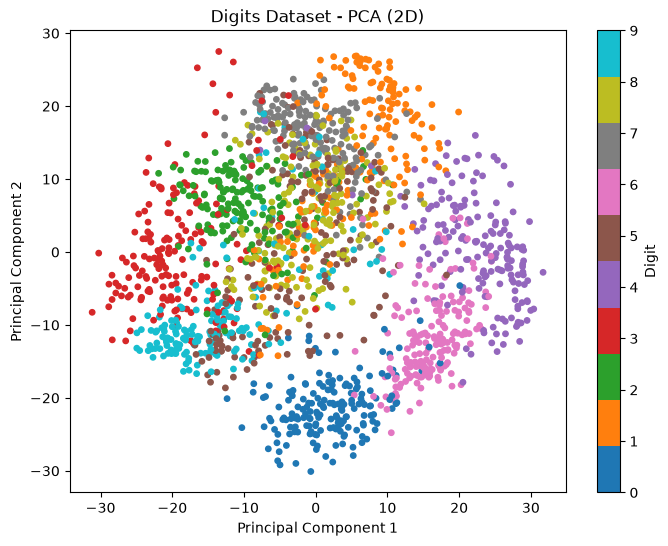

In [5]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=y,
    cmap='tab10',
    s=15
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Digits Dataset - PCA (2D)")
plt.colorbar(label="Digit")
plt.show()

In [6]:
# Split PCA data
X_train_pca, X_test_pca, y_train_pca, y_test_pca = train_test_split(
    X_pca, y, test_size=0.2, random_state=42
)

# Train KNN
knn_pca = KNeighborsClassifier(n_neighbors=5)
knn_pca.fit(X_train_pca, y_train_pca)

# Prediction
y_pred_pca = knn_pca.predict(X_test_pca)

# Accuracy
accuracy_pca = accuracy_score(y_test_pca, y_pred_pca)

print("Accuracy after PCA:",
      accuracy_pca)

Accuracy after PCA: 0.6555555555555556


In [7]:
# Apply t-SNE
tsne = TSNE(
    n_components=2,
    random_state=42,
    perplexity=30
)

X_tsne = tsne.fit_transform(X)

print("t-SNE data shape:", X_tsne.shape)

t-SNE data shape: (1797, 2)


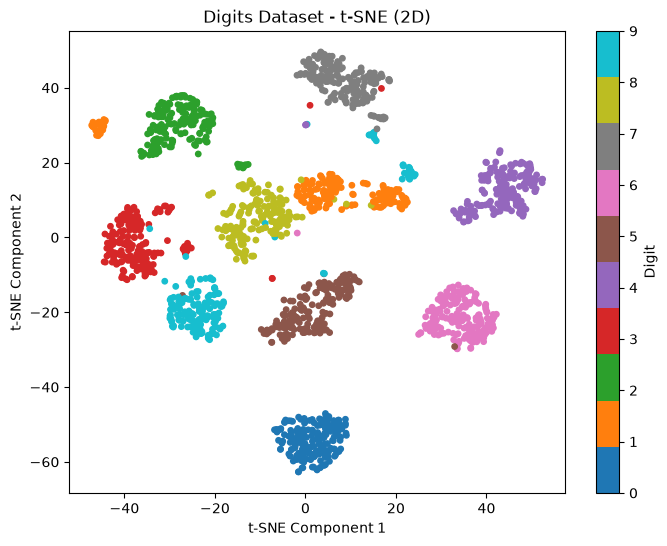

In [8]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_tsne[:, 0],
    X_tsne[:, 1],
    c=y,
    cmap='tab10',
    s=15
)

plt.xlabel("t-SNE Component 1")
plt.ylabel("t-SNE Component 2")
plt.title("Digits Dataset - t-SNE (2D)")
plt.colorbar(label="Digit")
plt.show()

In [9]:
# Split t-SNE data
X_train_tsne, X_test_tsne, y_train_tsne, y_test_tsne = train_test_split(
    X_tsne, y, test_size=0.2, random_state=42
)

# Train KNN
knn_tsne = KNeighborsClassifier(n_neighbors=5)
knn_tsne.fit(X_train_tsne, y_train_tsne)

# Prediction
y_pred_tsne = knn_tsne.predict(X_test_tsne)

# Accuracy
accuracy_tsne = accuracy_score(y_test_tsne, y_pred_tsne)

print("Accuracy after t-SNE:",
      accuracy_tsne)

Accuracy after t-SNE: 0.9833333333333333


In [10]:
print("-----------------------------------")
print("Accuracy Comparison")
print("-----------------------------------")

print("Original 64 features :", accuracy_original)
print("PCA 2 features       :", accuracy_pca)
print("t-SNE 2 features     :", accuracy_tsne)

-----------------------------------
Accuracy Comparison
-----------------------------------
Original 64 features : 0.9861111111111112
PCA 2 features       : 0.6555555555555556
t-SNE 2 features     : 0.9833333333333333


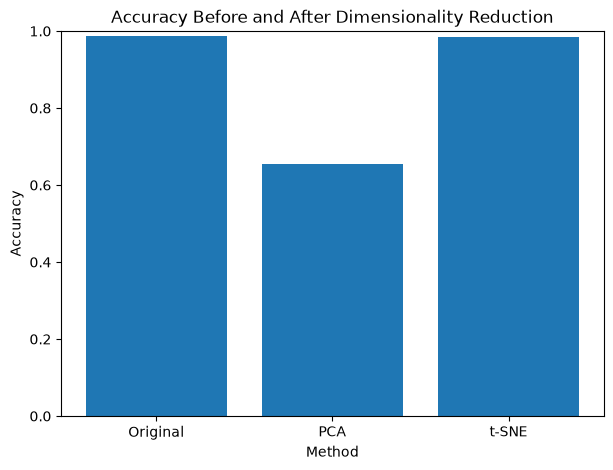

In [11]:
methods = ["Original", "PCA", "t-SNE"]
accuracies = [
    accuracy_original,
    accuracy_pca,
    accuracy_tsne
]

plt.figure(figsize=(7, 5))
plt.bar(methods, accuracies)

plt.ylabel("Accuracy")
plt.xlabel("Method")
plt.title("Accuracy Before and After Dimensionality Reduction")
plt.ylim(0, 1)

plt.show()